# Case 6 - Can foundation models manage risk? Zero-shot VaR and ES with conformal calibration

Master - Neural Networks and Deep Learning (NN) - Prof. Daniel Traian Pele

Bucharest University of Economic Studies - Romanian Academy, Institute for Economic Forecasting

In [1]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/cases/C6_foundation_risk')

In [2]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "en"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Paper.** Jheng, S.-L., Tak, R., Găman, Ș., Mazurencu-Marinescu-Pele, M. & Pele, D. T. (2026). Can foundation models manage risk?
Zero-shot VaR and ES forecasting with conformal calibration in CEE markets. *Economic Computation and Economic Cybernetics Studies and Research*,
60(2), 267-290. doi:10.24818/18423264/60.2.26.14

**What we do here.** (1) Compute daily log returns of eight shares of the Bucharest Stock Exchange (BVB). (2) Forecast, one day ahead, the 1 % and 2.5 %
Value-at-Risk (VaR) and the 2.5 % Expected Shortfall (ES) with three benchmarks (historical simulation, GJR-GARCH with skewed-t innovations, an AR(1)
model with split conformal prediction) and with two time series foundation models (TSFMs) used *zero-shot*: Chronos-2 and TimesFM 2.5.
(3) Wrap the foundation models in the paper's rolling conformal calibration. (4) Backtest everything with the Kupiec, Christoffersen and Acerbi-Székely
tests, the Basel traffic light, the tick loss, the FZ0 loss and Diebold-Mariano (DM) tests. (5) Translate the result into a daily risk limit.

**Classroom adaptation.** The paper uses ten series (five CEE stock indices and five exchange rates), January 2018 - December 2025 out of sample, and
also Moirai 2.0 and a conformal LSTM (Long Short-Term Memory) network. We use eight individual Romanian shares, January 2018 - November 2026 out of sample,
the two foundation models with direct quantile heads and the three benchmarks above. The foundation-model forecasts are cached in `cache/`;
delete the folder to recompute them (about 10 minutes on a laptop).

## 1. Data: eight BVB shares

In [3]:
import torch                                   # imported first (before scipy-heavy libraries); used by the foundation models
import scipy.stats as st
torch.set_num_threads(4)
STOCKS = ["TLV", "BRD", "SNP", "SNG", "SNN", "TGN", "EL", "TEL"]
NAME = {"TLV": "Banca Transilvania", "BRD": "BRD - Groupe Société Générale", "SNP": "OMV Petrom", "SNG": "Romgaz",
        "SNN": "Nuclearelectrica", "TGN": "Transgaz", "EL": "Electrica", "TEL": "Transelectrica"}
START, OOS = "2015-01-01", "2018-01-01"         # inputs from 2015 (clean adjusted prices); out-of-sample evaluation from 2018
LEVELS = [0.01, 0.025]                         # VaR levels as in the paper: 1 % (Basel) and 2.5 % (ES reference level)
W, CTX = 250, 512                              # rolling window of the benchmarks and of the conformal wrapper; context of the foundation models
P, V = cu.bvb_daily(), cu.bvb_daily("volume")
R = {}
for s in STOCKS:
    p = P[s].where(V[s] > 0).dropna().loc[START:]          # trading days only: the data file also lists holidays with zero volume
    R[s] = (100 * np.log(p).diff()).dropna()   # daily log returns in percent, each share on its own trading days
desc = pd.DataFrame({s: {"N": len(r.loc[OOS:]), "Mean": r.loc[OOS:].mean(), "Std": r.loc[OOS:].std(), "Skew": r.loc[OOS:].skew(),
                         "Kurt": r.loc[OOS:].kurt() + 3, "Min": r.loc[OOS:].min(), "Max": r.loc[OOS:].max(),
                         "Zero": 100 * (r.loc[OOS:] == 0).mean()} for s, r in R.items()}).T
print("returns in percent, out-of-sample period", OOS, "-", max(r.index.max() for r in R.values()).date())
desc.round(3)

returns in percent, out-of-sample period 2018-01-01 - 2026-11-06


,N,Mean,Std,Skew,Kurt,Min,Max,Zero
TLV,2205.0,0.094,1.587,-1.373,26.247,-22.207,11.171,8.254
BRD,2207.0,0.070,1.634,-0.523,13.517,-18.172,10.338,7.793
SNP,2207.0,0.112,1.494,-0.781,14.873,-14.978,9.992,7.793
SNG,2207.0,0.108,1.432,-0.331,7.890,-11.035,6.998,9.198
SNN,2207.0,0.139,1.560,0.266,8.188,-9.421,11.251,8.654
TGN,2207.0,0.078,1.574,0.048,8.752,-10.135,11.099,11.056
EL,2207.0,0.083,1.724,0.129,9.243,-11.778,14.383,9.787
TEL,2207.0,0.073,1.634,0.050,7.263,-9.317,7.636,15.632


In [4]:
cu.write_table(desc[["N", "Mean", "Std", "Skew", "Kurt", "Min", "Max", "Zero"]], "desc",
               [("Share", "Acțiunea"), ("$N$", "$N$"), ("Mean", "Media"), ("Std.\\ dev.", "Abaterea std."), ("Skewness", "Asimetria"),
                ("Kurtosis", "Aplatizarea"), ("Min", "Min"), ("Max", "Max"), ("Zero days (\\%)", "Zile fără variație (\\%)")],
               digits={"N": 0, "Mean": 3, "Std": 2, "Skew": 2, "Kurt": 1, "Min": 1, "Max": 1, "Zero": 1})

## 2. Benchmarks: historical simulation, GJR-GARCH, AR(1) with conformal prediction

In [5]:
import os, warnings
from arch import arch_model
from joblib import Parallel, delayed
os.makedirs("cache", exist_ok=True)

def hs(r):
    """Historical simulation: empirical alpha-quantile and tail mean of the last W returns."""
    x, out = r.values, {}
    for a in LEVELS:
        v, e = np.full(len(x), np.nan), np.full(len(x), np.nan)
        for t in range(W, len(x)):
            w = x[t - W:t]; v[t] = np.quantile(w, a); e[t] = w[w <= v[t]].mean()
        out[(a, "VaR")], out[(a, "ES")] = v, e
    return pd.DataFrame(out, index=r.index)

def gjr_one(r, t0):
    """GJR-GARCH(1,1) with skewed-t innovations, re-estimated every day on the last W returns (paper eq. 3)."""
    warnings.filterwarnings("ignore")
    x, rows = r.values, []
    u = (np.arange(400) + 0.5) / 400
    for t in range(t0, len(x)):
        am = arch_model(x[t - W:t], mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="skewt")
        res = am.fit(disp="off", show_warning=False)
        f = res.forecast(horizon=1, reindex=False)
        mu, sig = f.mean.values[-1, 0], np.sqrt(f.variance.values[-1, 0])
        row = []
        for a in LEVELS:
            z = am.distribution.ppf(u * a, res.params[-2:].values)          # quantiles of the standardised skewed-t below alpha
            q = am.distribution.ppf([a], res.params[-2:].values)[0]          # alpha-quantile of the standardised skewed-t
            row += [mu + sig * q, mu + sig * z.mean()]                      # VaR and ES (mean of the quantiles below alpha)
        rows.append(row)
    cols = pd.MultiIndex.from_tuples([(a, k) for a in LEVELS for k in ("VaR", "ES")])
    return pd.DataFrame(rows, index=r.index[t0:], columns=cols)

def ar_cp(r):
    """AR(1) point forecast on the last W returns + split conformal VaR/ES from the last W one-step residuals (paper eq. 4)."""
    x = r.values; n = len(x); rhat = np.full(n, np.nan)
    for t in range(W + 1, n):
        y, z = x[t - W:t], x[t - W - 1:t - 1]
        b = np.cov(z, y, bias=True)[0, 1] / z.var(); a0 = y.mean() - b * z.mean()
        rhat[t] = a0 + b * x[t - 1]
    e = x - rhat; out = {}
    for a in LEVELS:
        v, es = np.full(n, np.nan), np.full(n, np.nan)
        for t in range(2 * W + 1, n):
            c = e[t - W:t]; q = np.quantile(c, a); v[t] = rhat[t] + q; es[t] = rhat[t] + c[c <= q].mean()
        out[(a, "VaR")], out[(a, "ES")] = v, es
    return pd.DataFrame(out, index=r.index)

FC = {}
FC["HS"] = {s: hs(r) for s, r in R.items()}
FC["AR-CP"] = {s: ar_cp(r) for s, r in R.items()}
path = "cache/gjr_garch.csv.gz"
if os.path.exists(path):
    g = pd.read_csv(path, index_col=[0, 1], header=[0, 1], parse_dates=[1])
    g.columns = pd.MultiIndex.from_tuples([(float(a), k) for a, k in g.columns])
    FC["GJR-GARCH"] = {s: g.loc[s] for s in STOCKS}
else:
    t0 = {s: max(W, int(np.searchsorted(R[s].index, pd.Timestamp(OOS)))) for s in STOCKS}
    res = Parallel(n_jobs=4)(delayed(gjr_one)(R[s], t0[s]) for s in STOCKS)      # about 18,000 daily re-estimations
    FC["GJR-GARCH"] = dict(zip(STOCKS, res))
    pd.concat(FC["GJR-GARCH"], names=["stock", "date"]).to_csv(path)
print({m: len(FC[m]) for m in FC})

{'HS': 8, 'AR-CP': 8, 'GJR-GARCH': 8}


## 3. Foundation models, zero-shot: Chronos-2 and TimesFM 2.5

In [6]:
TAU = np.round(np.arange(0.1, 0.91, 0.1), 2)          # the nine deciles returned by both models (paper, section 3.2.3)

def windows(r):
    x = r.values.astype("float32")
    return [x[t - CTX:t] for t in range(CTX, len(x))], r.index[CTX:]

def run_chronos():
    from chronos import BaseChronosPipeline
    dev = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
    pipe = BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map=dev)
    out = {}
    for s, r in R.items():
        xs, idx = windows(r); qs = []
        for i in range(0, len(xs), 256):
            q, _ = pipe.predict_quantiles([torch.tensor(v) for v in xs[i:i + 256]], prediction_length=1, quantile_levels=list(TAU))
            qs += [qq[0, 0].float().cpu().numpy() for qq in q]
        out[s] = pd.DataFrame(np.array(qs), index=idx, columns=TAU)
    return out

def run_timesfm():
    import timesfm
    m = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
    if torch.backends.mps.is_available():                                # Apple GPU: about 200 forecasts per second (float32 inputs)
        m.model.device = torch.device("mps"); m.model.to("mps")
    m.compile(timesfm.ForecastConfig(max_context=CTX, max_horizon=128, normalize_inputs=True,
                                     use_continuous_quantile_head=True, per_core_batch_size=256))
    out = {}
    for s, r in R.items():
        xs, idx = windows(r)
        n = len(xs); xs = xs + [xs[-1]] * (-n % 256)                       # full batches of 256 (the GPU accepts float32 only)
        _, q = m.forecast(horizon=1, inputs=[v.astype("float32") for v in xs]); q = q[:n]
        out[s] = pd.DataFrame(q[:, 0, 1:], index=idx, columns=TAU)       # q[:, 0, 0] is the mean, then the deciles 0.1 ... 0.9
    return out

QF = {}
for name, fn in (("Chronos-2", run_chronos), ("TimesFM-2.5", run_timesfm)):
    path = f"cache/{name}_deciles.csv.gz"
    if os.path.exists(path):
        q = pd.read_csv(path, index_col=[0, 1], parse_dates=[1]); q.columns = TAU
        QF[name] = {s: q.loc[s] for s in STOCKS}
    else:
        import time; t_ = time.time()
        QF[name] = fn()
        pd.concat(QF[name], names=["stock", "date"]).to_csv(path)
        print(f"{name}: {time.time() - t_:.0f} s")
print(QF["Chronos-2"]["TLV"].tail(3).round(3))

              0.1    0.2    0.3    0.4    0.5    0.6    0.7    0.8    0.9
date                                                                     
2026-11-04 -0.990 -0.506 -0.226 -0.033  0.111  0.264  0.464  0.761  1.237
2026-11-05 -1.038 -0.544 -0.257 -0.059  0.090  0.246  0.447  0.744  1.218
2026-11-06 -1.017 -0.527 -0.254 -0.073  0.057  0.191  0.374  0.655  1.126


In [7]:
NU = np.concatenate([np.linspace(2.1, 10, 80), np.linspace(10.5, 60, 100)])

def t_match(Q):
    """Student-t quantile matching (paper, section 3.2.3): for each forecast choose (mu, sigma, nu) minimising
    sum_k (q_k - mu - sigma * t_nu^{-1}(tau_k))^2. For a given nu the least-squares mu, sigma are closed form; nu is searched on a fine grid."""
    q = Q.values; best = np.full(len(q), np.inf); par = np.zeros((len(q), 3))
    for nu in NU:
        z = st.t.ppf(TAU, nu); zc = z - z.mean()
        sig = (q - q.mean(1, keepdims=True)) @ zc / (zc @ zc)
        mu = q.mean(1) - sig * z.mean()
        sse = ((q - mu[:, None] - sig[:, None] * z) ** 2).sum(1)
        ok = (sse < best) & (sig > 0)
        best[ok] = sse[ok]; par[ok] = np.c_[mu, sig, np.full(len(q), nu)][ok]
    return par

def t_var_es(par, a):
    mu, sig, nu = par.T
    ta = st.t.ppf(a, nu)
    es = mu - sig * st.t.pdf(ta, nu) / a * (nu + ta ** 2) / (nu - 1)     # ES of a location-scale Student t (left tail)
    return mu + sig * ta, es

for name in QF:
    FC[name] = {}
    for s in STOCKS:
        par = t_match(QF[name][s]); d = {}
        for a in LEVELS:
            d[(a, "VaR")], d[(a, "ES")] = t_var_es(par, a)
        FC[name][s] = pd.DataFrame(d, index=QF[name][s].index)
        FC[name][s]["nu"] = par[:, 2]
print("median fitted degrees of freedom:", {n: round(float(np.median(np.concatenate([FC[n][s]["nu"] for s in STOCKS]))), 1) for n in QF})

median fitted degrees of freedom: {'Chronos-2': 2.2, 'TimesFM-2.5': 5.6}


## 4. The conformal wrapper

In [8]:
def conformal(fc, r):
    """Rolling conformal calibration (paper eqs. 5-6): s_i = r_i - VaR_raw_i over the last W days; VaR_conf = VaR_raw + Q_alpha(s).
    The ES forecast is shifted by the same amount (our choice for the ES of the wrapped model)."""
    x = r.reindex(fc.index).values; out = {}; shift = {}
    for a in LEVELS:
        v = fc[(a, "VaR")].values; sc = x - v
        sh = np.full(len(v), np.nan)
        for t in range(W, len(v)):
            sh[t] = np.quantile(sc[t - W:t], a)
        out[(a, "VaR")], out[(a, "ES")], shift[a] = v + sh, fc[(a, "ES")].values + sh, sh
    o = pd.DataFrame(out, index=fc.index)
    for a in LEVELS:
        o[("shift", a)] = shift[a]
    return o

for name in list(QF):
    FC[name + "-Conf"] = {s: conformal(FC[name][s], R[s]) for s in STOCKS}
MODELS = ["HS", "GJR-GARCH", "AR-CP", "Chronos-2", "TimesFM-2.5", "Chronos-2-Conf", "TimesFM-2.5-Conf"]
LAB = {"HS": ("Historical simulation", "Simulare istorică"), "GJR-GARCH": ("GJR-GARCH", "GJR-GARCH"),
       "AR-CP": ("AR(1) + conformal", "AR(1) + conformal"), "Chronos-2": ("Chronos-2, zero-shot", "Chronos-2, zero-shot"),
       "TimesFM-2.5": ("TimesFM 2.5, zero-shot", "TimesFM 2.5, zero-shot"), "Chronos-2-Conf": ("Chronos-2, conformal", "Chronos-2, conformal"),
       "TimesFM-2.5-Conf": ("TimesFM 2.5, conformal", "TimesFM 2.5, conformal")}
# common out-of-sample sample: every model available for that share and day
EV = {}
for s in STOCKS:
    parts = {m: FC[m][s][[(a, k) for a in LEVELS for k in ("VaR", "ES")]] for m in MODELS}
    df = pd.concat(parts, axis=1).loc[OOS:]
    df[("r", "r", "r")] = R[s].reindex(df.index)
    EV[s] = df.dropna()
nOOS = sum(len(EV[s]) for s in STOCKS)
oos_start, oos_end = min(EV[s].index.min() for s in STOCKS), max(EV[s].index.max() for s in STOCKS)
print("out-of-sample forecasts per model and level:", nOOS, "|", oos_start.date(), "-", oos_end.date())

out-of-sample forecasts per model and level: 17572 | 2018-01-17 - 2026-11-06


## 5. Backtests

In [9]:
def kupiec(I, a):
    T, N = len(I), I.sum(); ah = N / T
    ll0 = (T - N) * np.log(1 - a) + N * np.log(a)
    ll1 = (T - N) * np.log(1 - ah) + (N * np.log(ah) if N > 0 else 0)
    lr = -2 * (ll0 - ll1); return lr, 1 - st.chi2.cdf(lr, 1)

def christoffersen(I, a):
    """Conditional coverage: LR_CC = LR_UC + LR_IND (paper eq. 8)."""
    lr_uc, _ = kupiec(I, a)
    i0, i1 = I[:-1], I[1:]
    n00, n01 = ((i0 == 0) & (i1 == 0)).sum(), ((i0 == 0) & (i1 == 1)).sum()
    n10, n11 = ((i0 == 1) & (i1 == 0)).sum(), ((i0 == 1) & (i1 == 1)).sum()
    L = lambda p, k0, k1: (k0 * np.log(1 - p) if k0 else 0) + (k1 * np.log(p) if k1 and p > 0 else 0)
    p01, p11, p = n01 / max(n00 + n01, 1), n11 / max(n10 + n11, 1), (n01 + n11) / max(n00 + n01 + n10 + n11, 1)
    lr_ind = -2 * (L(p, n00 + n10, n01 + n11) - L(p01, n00, n01) - L(p11, n10, n11))
    lr = lr_uc + lr_ind; return lr, 1 - st.chi2.cdf(lr, 2)

def z2(r, v, es, a, B=1000, seed=20261108):
    """Acerbi-Szekely Z2 (paper eq. 9; ES < 0 in return units): Z2 = 1 - sum(I r / ES) / (T a); negative = ES too mild.
    One-sided bootstrap p-value with centred replications, B = 1000 (paper, section 3.2.5)."""
    I = (r < v).astype(float); T = len(r)
    obs = 1 - (I * r / es).sum() / (T * a)
    rng = np.random.default_rng(seed); idx = rng.integers(0, T, (B, T))
    Ib, rb, eb = I[idx], r[idx], es[idx]
    keep = Ib.sum(1) > 0
    zb = 1 - (Ib * rb / eb).sum(1) / (T * a)
    pv = np.mean((zb[keep] - obs) <= obs)
    return obs, pv

tick = lambda r, v, a: (a - (r < v)) * (r - v)                    # quantile (tick) loss of a VaR forecast
def fz0(r, v, es, a):
    """FZ0 loss of Patton, Ziegel & Chen (2019) for the pair (VaR, ES), ES < 0."""
    return -((r <= v) * (v - r)) / (a * es) + v / es + np.log(-es) - 1

def zone(n):                                                       # Basel traffic light for 250 days at 1 %
    return "green" if n <= 4 else ("yellow" if n <= 9 else "red")

rows, blocks, LOSS = {}, {}, {}
for m in MODELS:
    rec = {"viol1": [], "kup": 0, "cc": 0, "z2": [], "z2rej": 0, "viol25": [], "tick1": [], "fz": [], "var1": []}
    zs = []
    for s in STOCKS:
        e = EV[s]; r = e[("r", "r", "r")].values
        v1, v25, es25 = e[(m, 0.01, "VaR")].values, e[(m, 0.025, "VaR")].values, e[(m, 0.025, "ES")].values
        I1 = (r < v1).astype(int)
        rec["viol1"].append(100 * I1.mean()); rec["viol25"].append(100 * (r < v25).mean()); rec["var1"].append(v1.mean())
        rec["kup"] += kupiec(I1, 0.01)[1] < 0.05; rec["cc"] += christoffersen(I1, 0.01)[1] < 0.05
        zz, pz = z2(r, v25, es25, 0.025); rec["z2"].append(zz); rec["z2rej"] += pz < 0.05
        rec["tick1"].append(tick(r, v1, 0.01).mean()); rec["fz"].append(fz0(r, v25, es25, 0.025).mean())
        nb = len(I1) // 250
        zs += [zone(I1[b * 250:(b + 1) * 250].sum()) for b in range(nb)]
        blocks[(m, s)] = 100 * np.mean([zone(I1[b * 250:(b + 1) * 250].sum()) == "green" for b in range(nb)])
        LOSS[(m, s)] = pd.Series(tick(r, v1, 0.01), index=e.index)
    rows[m] = {"Viol1": np.mean(rec["viol1"]), "Kup": rec["kup"], "CC": rec["cc"], "Green": 100 * np.mean([z == "green" for z in zs]),
               "Red": 100 * np.mean([z == "red" for z in zs]), "Tick": 100 * np.mean(rec["tick1"]), "Viol25": np.mean(rec["viol25"]),
               "Ztwo": np.mean(rec["z2"]), "Zmin": np.min(rec["z2"]), "Zmax": np.max(rec["z2"]), "Zrej": rec["z2rej"], "FZ": np.mean(rec["fz"]),
               "VaRone": np.mean(rec["var1"]), "nBlocks": len(zs)}
res = pd.DataFrame(rows).T
VIOL = pd.DataFrame({m: {s: 100 * (EV[s][("r", "r", "r")] < EV[s][(m, 0.01, "VaR")]).mean() for s in STOCKS} for m in MODELS})
GREEN = pd.DataFrame({m: {s: blocks[(m, s)] for s in STOCKS} for m in MODELS})
res.round(3)

,Viol1,Kup,CC,Green,Red,Tick,Viol25,Ztwo,Zmin,Zmax,Zrej,FZ,VaRone,nBlocks
HS,1.707,8.0,8.0,53.125,1.562,6.501,3.392,-0.494,-0.744,-0.359,8.0,1.608,-3.865,64.0
GJR-GARCH,1.366,2.0,2.0,78.125,0.000,5.681,3.238,-0.322,-0.486,-0.131,5.0,1.445,-3.863,64.0
AR-CP,1.724,8.0,8.0,54.688,1.562,6.523,3.352,-0.491,-0.664,-0.378,8.0,1.611,-3.872,64.0
Chronos-2,0.484,8.0,5.0,100.000,0.000,6.103,2.100,0.342,0.257,0.508,0.0,1.490,-5.191,64.0
TimesFM-2.5,2.123,8.0,8.0,40.625,9.375,5.901,4.536,-0.938,-1.056,-0.706,8.0,1.508,-3.189,64.0
Chronos-2-Conf,1.332,2.0,1.0,81.250,0.000,6.060,3.005,0.096,0.009,0.231,0.0,1.521,-4.283,64.0
TimesFM-2.5-Conf,1.463,5.0,4.0,60.938,0.000,5.859,3.113,-0.352,-0.413,-0.266,7.0,1.476,-3.759,64.0


In [10]:
def dm(m, bench):
    """Diebold-Mariano on the daily tick-loss differential, averaged over the eight shares; Newey-West variance."""
    d = pd.concat({s: LOSS[(m, s)] - LOSS[(bench, s)] for s in STOCKS}, axis=1).mean(1).dropna().values
    T = len(d); L = int(np.floor(4 * (T / 100) ** (2 / 9))); dc = d - d.mean()
    g = [dc @ dc / T] + [dc[k:] @ dc[:-k] / T for k in range(1, L + 1)]
    var = g[0] + 2 * sum((1 - k / (L + 1)) * g[k] for k in range(1, L + 1))
    stat = d.mean() / np.sqrt(var / T); return stat, 2 * (1 - st.norm.cdf(abs(stat)))
res["DMhs"] = [np.nan if m == "HS" else dm(m, "HS")[0] for m in MODELS]
res["DMgjr"] = [np.nan if m == "GJR-GARCH" else dm(m, "GJR-GARCH")[0] for m in MODELS]
res["pDMgjr"] = [np.nan if m == "GJR-GARCH" else dm(m, "GJR-GARCH")[1] for m in MODELS]
lab = lambda m: LAB[m]
tv = res[["Viol1", "Kup", "CC", "Green", "Tick", "DMhs", "DMgjr"]].copy(); tv.index = [lab(m) for m in MODELS]
tv["Dev"] = (tv["Viol1"] - 1).abs()
cu.write_table(tv[["Viol1", "Kup", "CC", "Green", "Tick", "DMhs", "DMgjr"]], "var",
               [("Model", "Modelul"), ("Violations (\\%)", "Depășiri (\\%)"), ("Kupiec rej.", "Resp.\\ Kupiec"), ("Christoff.\\ rej.", "Resp.\\ Christoff."),
                ("Green (\\%)", "Verde (\\%)"), ("Tick loss (bp)", "Pierdere tick (pb)"), ("DM vs HS", "DM față de SI"), ("DM vs GJR", "DM față de GJR")],
               digits={"Viol1": 2, "Kup": 0, "CC": 0, "Green": 1, "Tick": 2, "DMhs": 2, "DMgjr": 2},
               best={"Kup": "min", "CC": "min", "Green": "max", "Tick": "min"})
te = res[["Viol25", "Ztwo", "Zmin", "Zmax", "Zrej", "FZ"]].copy(); te.index = [lab(m) for m in MODELS]
cu.write_table(te, "es",
               [("Model", "Modelul"), ("Violations (\\%)", "Depășiri (\\%)"), ("Mean $Z_2$", "$Z_2$ mediu"), ("Min $Z_2$", "$Z_2$ minim"),
                ("Max $Z_2$", "$Z_2$ maxim"), ("$Z_2$ rej.", "Resp.\\ $Z_2$"), ("FZ0 loss", "Pierdere FZ0")],
               digits={"Viol25": 2, "Ztwo": 2, "Zmin": 2, "Zmax": 2, "Zrej": 0, "FZ": 3}, best={"Ztwo": "absmin", "Zrej": "min", "FZ": "min"})
res[["Viol1", "Kup", "CC", "Green", "Red", "Tick", "DMhs", "DMgjr", "pDMgjr", "Viol25", "Ztwo", "Zrej", "FZ"]].round(3)

,Viol1,Kup,CC,Green,Red,Tick,DMhs,DMgjr,pDMgjr,Viol25,Ztwo,Zrej,FZ
HS,1.707,8.0,8.0,53.125,1.562,6.501,NaN,2.271,0.023,3.392,-0.494,8.0,1.608
GJR-GARCH,1.366,2.0,2.0,78.125,0.000,5.681,-2.271,NaN,NaN,3.238,-0.322,5.0,1.445
AR-CP,1.724,8.0,8.0,54.688,1.562,6.523,0.820,2.401,0.016,3.352,-0.491,8.0,1.611
Chronos-2,0.484,8.0,5.0,100.000,0.000,6.103,-0.847,2.699,0.007,2.100,0.342,0.0,1.490
TimesFM-2.5,2.123,8.0,8.0,40.625,9.375,5.901,-3.242,1.064,0.287,4.536,-0.938,8.0,1.508
Chronos-2-Conf,1.332,2.0,1.0,81.250,0.000,6.060,-0.995,3.425,0.001,3.005,0.096,0.0,1.521
TimesFM-2.5-Conf,1.463,5.0,4.0,60.938,0.000,5.859,-2.580,1.364,0.173,3.113,-0.352,7.0,1.476


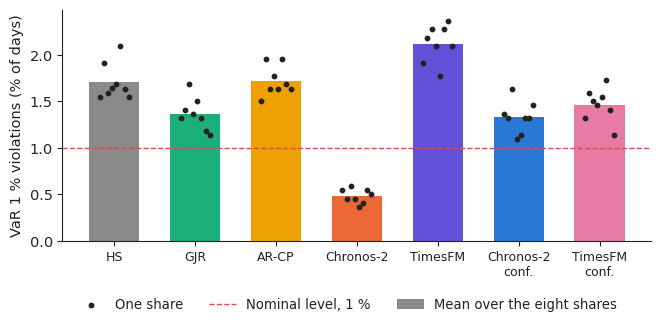

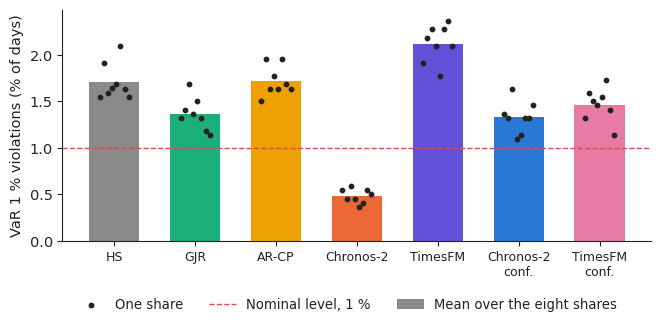

In [11]:
COL = {"HS": cu.MUTED, "GJR-GARCH": cu.SERIES[2], "AR-CP": cu.SERIES[3], "Chronos-2": cu.SERIES[1], "TimesFM-2.5": cu.SERIES[6],
       "Chronos-2-Conf": cu.SERIES[0], "TimesFM-2.5-Conf": cu.SERIES[4]}
SHORT = {"HS": ("HS", "SI"), "GJR-GARCH": ("GJR", "GJR"), "AR-CP": ("AR-CP", "AR-CP"), "Chronos-2": ("Chronos-2", "Chronos-2"),
         "TimesFM-2.5": ("TimesFM", "TimesFM"), "Chronos-2-Conf": ("Chronos-2\nconf.", "Chronos-2\nconf."),
         "TimesFM-2.5-Conf": ("TimesFM\nconf.", "TimesFM\nconf.")}
def fig_viol(lang):
    fig, ax = plt.subplots(figsize=(7.6, 3.0))
    xs = np.arange(len(MODELS))
    ax.bar(xs, [VIOL[m].mean() for m in MODELS], color=[COL[m] for m in MODELS], width=0.62,
           label=cu.T(lang, "Mean over the eight shares", "Media celor opt acțiuni"))
    for i, m in enumerate(MODELS):
        ax.scatter(np.full(len(STOCKS), i) + np.linspace(-0.18, 0.18, len(STOCKS)), VIOL[m].values, s=10, color=cu.INK, zorder=3,
                   label=cu.T(lang, "One share", "O acțiune") if i == 0 else "_")
    ax.axhline(1, color=cu.EVENT, ls="--", lw=1, label=cu.T(lang, "Nominal level, 1 %", "Nivelul nominal, 1 %"))
    ax.set_xticks(xs); ax.set_xticklabels([cu.T(lang, *SHORT[m]) for m in MODELS], fontsize=9)
    ax.set_ylabel(cu.T(lang, "VaR 1 % violations (% of days)", "Depășiri VaR 1 % (% din zile)"))
    cu.comma_axis(ax, lang)
    cu.legend_bottom(fig, ncol=3, y=-0.04)
    return fig
cu.save_both(fig_viol, "f2_violations", headline=True)

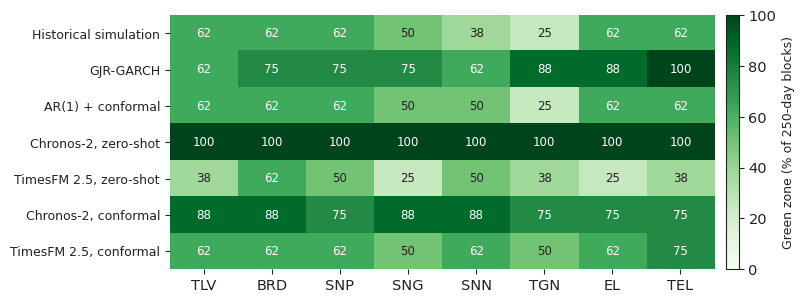

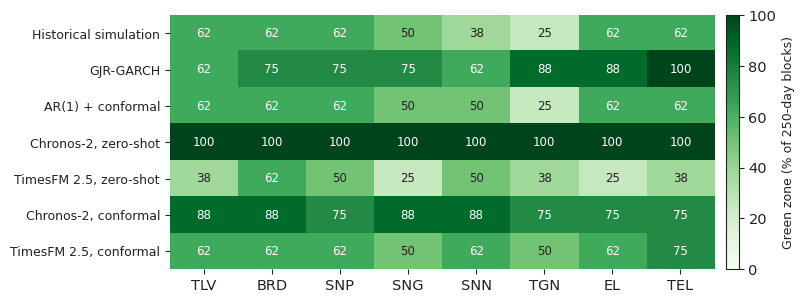

In [12]:
def fig_green(lang):
    fig, ax = plt.subplots(figsize=(7.4, 3.3))
    G = GREEN[MODELS].T.values
    im = ax.imshow(G, cmap="Greens", vmin=0, vmax=100, aspect="auto")
    for i in range(G.shape[0]):
        for j in range(G.shape[1]):
            ax.text(j, i, cu.fmt(G[i, j], 0, lang), ha="center", va="center", fontsize=8.5, color="white" if G[i, j] > 60 else cu.INK)
    ax.set_xticks(range(len(STOCKS))); ax.set_xticklabels(STOCKS)
    ax.set_yticks(range(len(MODELS))); ax.set_yticklabels([cu.T(lang, *LAB[m]) for m in MODELS], fontsize=9)
    for sp in ax.spines.values(): sp.set_visible(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    cb.set_label(cu.T(lang, "Green zone (% of 250-day blocks)", "Zona verde (% din blocurile de 250 de zile)"), fontsize=9)
    return fig
cu.save_both(fig_green, "f3_traffic_light")

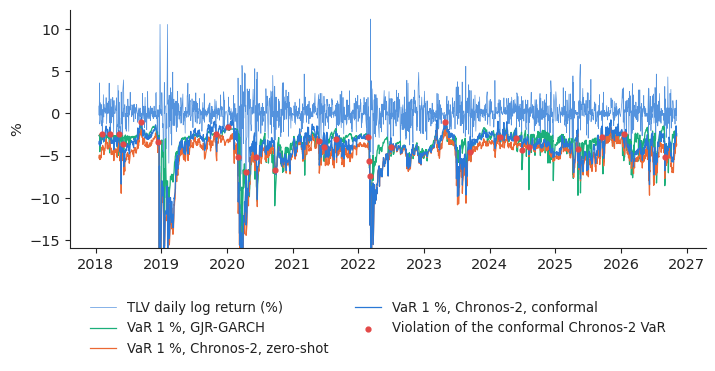

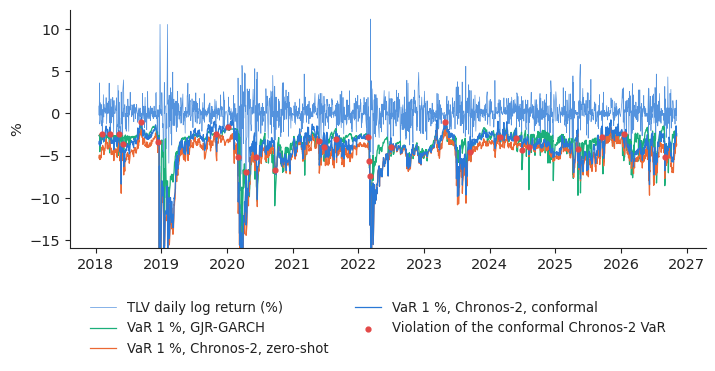

In [13]:
s0 = "TLV"; e0 = EV[s0]
def fig_path(lang):
    fig, ax = plt.subplots(figsize=(8.2, 3.1))
    r = e0[("r", "r", "r")]
    ax.plot(r.index, r, color=cu.PAL["RO"], lw=0.5, alpha=0.8, label=cu.T(lang, f"{s0} daily log return (%)", f"Randamentul zilnic {s0} (%)"))
    for m, ls in (("GJR-GARCH", "-"), ("Chronos-2", "-"), ("Chronos-2-Conf", "-")):
        ax.plot(e0.index, e0[(m, 0.01, "VaR")], color=COL[m], lw=0.9, ls=ls, label=cu.T(lang, "VaR 1 %, ", "VaR 1 %, ") + cu.T(lang, *LAB[m]))
    v = e0[("Chronos-2-Conf", 0.01, "VaR")]; br = r < v
    ax.scatter(r.index[br], r[br], s=12, color=cu.EVENT, zorder=4, label=cu.T(lang, "Violation of the conformal Chronos-2 VaR", "Depășire a VaR Chronos-2 conformal"))
    ax.set_ylabel("%"); ax.set_ylim(max(r.min() * 1.1, -16), r.max() * 1.1)
    cu.comma_axis(ax, lang)
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_path, "f1_var_path")

{'Chronos-2': 0.908, 'TimesFM-2.5': -0.57}


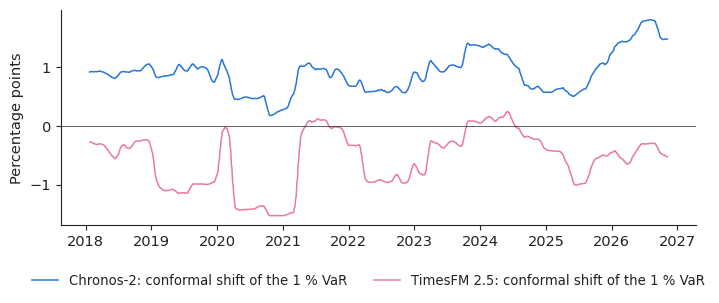

In [14]:
SH = {n: pd.concat({s: FC[n + "-Conf"][s][("shift", 0.01)] for s in STOCKS}, axis=1).loc[OOS:].mean(1) for n in QF}
def fig_shift(lang):
    fig, ax = plt.subplots(figsize=(8.2, 2.8))
    for n in QF:
        x = SH[n].rolling(21, min_periods=5).mean()
        ax.plot(x.index, x, color=COL[n + "-Conf"], lw=1.1, label=cu.T(lang, f"{LAB[n][0].split(',')[0]}: conformal shift of the 1 % VaR",
                                                                      f"{LAB[n][1].split(',')[0]}: corecția conformală a VaR 1 %"))
    ax.axhline(0, color=cu.INK, lw=0.5)
    ax.set_ylabel(cu.T(lang, "Percentage points", "Puncte procentuale"))
    cu.comma_axis(ax, lang)
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_shift, "f4_conformal_shift")
print({n: round(float(SH[n].mean()), 3) for n in SH})

## 6. From a backtest to a risk limit

In [15]:
POS = 10_000_000                                                   # 10 million RON in each share (a constant chosen for illustration)
lim = {m: np.mean([(POS * (1 - np.exp(EV[s][(m, 0.01, "VaR")] / 100))).mean() for s in STOCKS]) for m in MODELS}
exc = {m: 1000 * VIOL[m].mean() / 100 for m in MODELS}             # exceptions per 1,000 trading days
for m in MODELS:
    print(f"{m:18s} mean daily 1 % VaR limit {lim[m]:9,.0f} RON per 10 million RON | {exc[m]:5.1f} exceptions per 1,000 days")
best = res["Green"].idxmax()
cu.write_numbers({
    "nStocks": len(STOCKS), "nOOS": nOOS, "nBlocks": int(res.loc["HS", "nBlocks"]),
    "oosStart": (f"{oos_start:%d %B %Y}", f"{oos_start:%d.%m.%Y}"), "oosEnd": (f"{oos_end:%d %B %Y}", f"{oos_end:%d.%m.%Y}"),
    "kurtMin": desc["Kurt"].min(), "kurtMax": desc["Kurt"].max(), "zeroMin": desc["Zero"].min(), "zeroMax": desc["Zero"].max(),
    "vHS": res.loc["HS", "Viol1"], "vGJR": res.loc["GJR-GARCH", "Viol1"], "vAR": res.loc["AR-CP", "Viol1"],
    "vCh": res.loc["Chronos-2", "Viol1"], "vTf": res.loc["TimesFM-2.5", "Viol1"], "vChC": res.loc["Chronos-2-Conf", "Viol1"], "vTfC": res.loc["TimesFM-2.5-Conf", "Viol1"],
    "gHS": res.loc["HS", "Green"], "gGJR": res.loc["GJR-GARCH", "Green"], "gAR": res.loc["AR-CP", "Green"],
    "gCh": res.loc["Chronos-2", "Green"], "gTf": res.loc["TimesFM-2.5", "Green"], "gChC": res.loc["Chronos-2-Conf", "Green"], "gTfC": res.loc["TimesFM-2.5-Conf", "Green"],
    "kCh": int(res.loc["Chronos-2", "Kup"]), "kChC": int(res.loc["Chronos-2-Conf", "Kup"]), "kGJR": int(res.loc["GJR-GARCH", "Kup"]),
    "kTf": int(res.loc["TimesFM-2.5", "Kup"]), "kTfC": int(res.loc["TimesFM-2.5-Conf", "Kup"]), "kHS": int(res.loc["HS", "Kup"]),
    "zHS": res.loc["HS", "Ztwo"], "zGJR": res.loc["GJR-GARCH", "Ztwo"], "zCh": res.loc["Chronos-2", "Ztwo"], "zTf": res.loc["TimesFM-2.5", "Ztwo"],
    "zChC": res.loc["Chronos-2-Conf", "Ztwo"], "zTfC": res.loc["TimesFM-2.5-Conf", "Ztwo"], "zAR": res.loc["AR-CP", "Ztwo"],
    "fzBest": (LAB[res["FZ"].idxmin()][0], LAB[res["FZ"].idxmin()][1]), "tickBest": (LAB[res["Tick"].idxmin()][0], LAB[res["Tick"].idxmin()][1]),
    "greenBest": (LAB[best][0], LAB[best][1]),
    "dmChCgjr": res.loc["Chronos-2-Conf", "DMgjr"], "pdmChCgjr": res.loc["Chronos-2-Conf", "pDMgjr"],
    "dmChgjr": res.loc["Chronos-2", "DMgjr"], "pdmChgjr": res.loc["Chronos-2", "pDMgjr"],
    "dmChChs": res.loc["Chronos-2-Conf", "DMhs"],
    "shCh": SH["Chronos-2"].mean(), "shTf": SH["TimesFM-2.5"].mean(),
    "nuCh": float(np.median(np.concatenate([FC["Chronos-2"][s]["nu"] for s in STOCKS]))),
    "nuTf": float(np.median(np.concatenate([FC["TimesFM-2.5"][s]["nu"] for s in STOCKS]))),
    "limGJR": lim["GJR-GARCH"] / 1000, "limCh": lim["Chronos-2"] / 1000, "limChC": lim["Chronos-2-Conf"] / 1000, "limHS": lim["HS"] / 1000,
    "limTfC": lim["TimesFM-2.5-Conf"] / 1000,
    "limDiff": (lim["Chronos-2"] - lim["Chronos-2-Conf"]) / 1000,
    "excCh": exc["Chronos-2"], "excChC": exc["Chronos-2-Conf"], "excGJR": exc["GJR-GARCH"], "excHS": exc["HS"],
    "tlvViolCh": VIOL.loc["TLV", "Chronos-2"], "tlvViolChC": VIOL.loc["TLV", "Chronos-2-Conf"],
}, digits={"kurtMin": 1, "kurtMax": 1, "zeroMin": 1, "zeroMax": 1, "vHS": 2, "vGJR": 2, "vAR": 2, "vCh": 2, "vTf": 2, "vChC": 2, "vTfC": 2,
           "gHS": 1, "gGJR": 1, "gAR": 1, "gCh": 1, "gTf": 1, "gChC": 1, "gTfC": 1,
           "zHS": 2, "zGJR": 2, "zCh": 2, "zTf": 2, "zChC": 2, "zTfC": 2, "zAR": 2, "dmChCgjr": 2, "pdmChCgjr": 3, "dmChgjr": 2, "pdmChgjr": 3, "dmChChs": 2,
           "shCh": 2, "shTf": 2, "nuCh": 1, "nuTf": 1, "limGJR": 0, "limCh": 0, "limChC": 0, "limHS": 0, "limTfC": 0, "limDiff": 0,
           "excCh": 1, "excChC": 1, "excGJR": 1, "excHS": 1, "tlvViolCh": 2, "tlvViolChC": 2})

HS                 mean daily 1 % VaR limit   378,542 RON per 10 million RON |  17.1 exceptions per 1,000 days
GJR-GARCH          mean daily 1 % VaR limit   377,114 RON per 10 million RON |  13.7 exceptions per 1,000 days
AR-CP              mean daily 1 % VaR limit   379,169 RON per 10 million RON |  17.2 exceptions per 1,000 days
Chronos-2          mean daily 1 % VaR limit   503,584 RON per 10 million RON |   4.8 exceptions per 1,000 days
TimesFM-2.5        mean daily 1 % VaR limit   313,597 RON per 10 million RON |  21.2 exceptions per 1,000 days
Chronos-2-Conf     mean daily 1 % VaR limit   416,849 RON per 10 million RON |  13.3 exceptions per 1,000 days
TimesFM-2.5-Conf   mean daily 1 % VaR limit   368,294 RON per 10 million RON |  14.6 exceptions per 1,000 days


In [16]:
# slide-ready summary for the lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
for lang in ("en", "ro"):
    F = lambda v, nd=2: cu.fmt(float(v), nd, lang)
    t = lambda en, ro: ro if lang == "ro" else en
    lines = [
        t("\\textbf{Foundation models for tail risk} (Jheng, Tak, Găman, Mazurencu-Marinescu-Pele \\& Pele, 2026, ECECSR): zero-shot Chronos-2 reaches a 90\\,\\% Basel Green rate, as GJR-GARCH; with conformal calibration 96.7\\,\\%.",
          "\\textbf{Modele fundație pentru riscul extrem} (Jheng, Tak, Găman, Mazurencu-Marinescu-Pele și Pele, 2026, ECECSR): Chronos-2 zero-shot atinge o rată de 90\\,\\% în zona verde Basel, ca GJR-GARCH; cu calibrare conformală, 96,7\\,\\%."),
        t(f"Our replication on {len(STOCKS)} BVB shares, 2018--2026: 1\\,\\% VaR violations {F(res.loc['Chronos-2', 'Viol1'])}\\,\\% (Chronos-2), {F(res.loc['Chronos-2-Conf', 'Viol1'])}\\,\\% (conformal), {F(res.loc['GJR-GARCH', 'Viol1'])}\\,\\% (GJR-GARCH).",
          f"Replicarea noastră pe {len(STOCKS)} acțiuni BVB, 2018--2026: depășiri ale VaR 1\\,\\% de {F(res.loc['Chronos-2', 'Viol1'])}\\,\\% (Chronos-2), {F(res.loc['Chronos-2-Conf', 'Viol1'])}\\,\\% (conformal), {F(res.loc['GJR-GARCH', 'Viol1'])}\\,\\% (GJR-GARCH)."),
        t(f"Green zone: {F(res.loc['Chronos-2', 'Green'], 1)}\\,\\% raw vs {F(res.loc['Chronos-2-Conf', 'Green'], 1)}\\,\\% conformal (GJR-GARCH {F(res.loc['GJR-GARCH', 'Green'], 1)}\\,\\%).",
          f"Zona verde: {F(res.loc['Chronos-2', 'Green'], 1)}\\,\\% fără calibrare, {F(res.loc['Chronos-2-Conf', 'Green'], 1)}\\,\\% cu calibrare conformală (GJR-GARCH {F(res.loc['GJR-GARCH', 'Green'], 1)}\\,\\%)."),
        t("Decision: use a foundation model only inside a conformal wrapper and a backtest; the calibration layer, not the model size, delivers coverage.",
          "Decizia: folosiți un model fundație numai împreună cu calibrarea conformală și cu testarea retrospectivă; stratul de calibrare, nu mărimea modelului, asigură acoperirea."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Foundation models for tail risk} (Jheng, Tak, Găman, Mazurencu-Marinescu-Pele \& Pele, 2026, ECECSR): zero-shot Chronos-2 reaches a 90\,\% Basel Green rate, as GJR-GARCH; with conformal calibration 96.7\,\%.
  \item Our replication on 8 BVB shares, 2018--2026: 1\,\% VaR violations 0.48\,\% (Chronos-2), 1.33\,\% (conformal), 1.37\,\% (GJR-GARCH).
  \item Green zone: 100.0\,\% raw vs 81.2\,\% conformal (GJR-GARCH 78.1\,\%).
  \item Decision: use a foundation model only inside a conformal wrapper and a backtest; the calibration layer, not the model size, delivers coverage.
\end{itemize}



## Your turn
1. Replace the Student-t quantile matching by Chronos-2's native 1 % and 2.5 % quantiles (`quantile_levels=[0.01, 0.025]`). Are the raw violations closer to the nominal level?
2. Shorten the conformal window from 250 to 125 days and lengthen it to 500 days (the paper's robustness check). How do the Green-zone rate and the average VaR change?
3. Add the BET index of the Bucharest Stock Exchange or the EUR/RON exchange rate (download them yourself and document the source). Are the conclusions of the paper for Romania reproduced?